In [1]:
import numpy
import re
import math
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [8]:
class RegionOfInterest:
    def __init__(self, mz_values, mz_mean):
        self.values = mz_values
        self.mzmean = mz_mean
        print(mz_values, mz_mean)

def process_scans(scans, ppm, pmin):
    # Initialisation
    ROIs = [RegionOfInterest([mz], mz) for mz in scans[0]]
    
    # For each scan starting from the second one
    for s in range(1, len(scans)):
        current_scan = scans[s]
        
        for mz_value in current_scan:
            # Check if mz_value is close to any existing ROI
            found_roi = False
            for roi in ROIs:
                if abs(roi.mzmean - mz_value) <= ppm:
                    found_roi = True
                    roi.values.append(mz_value)
                    roi.mzmean = sum(roi.values) / len(roi.values)
                    break
            
            if not found_roi:
                # If mz_value doesn't belong to any existing ROI, create a new ROI
                new_roi = RegionOfInterest([mz_value], mz_value)
                ROIs.append(new_roi)

    # Check & Cleanup
    completed_ROIs = []
    for roi in ROIs:
        if len(roi.values) >= pmin:
            completed_ROIs.append(roi)

    return completed_ROIs

# Example usage:
# Assuming scans is a list of lists where each inner list represents the m/z values for a scan
# ppm is the mass accuracy in ppm, and pmin is the minimum number of centroids
scans = [
    [100.0, 101.0, 105.0],
    [100.2, 101.2, 105.2, 110.0],
    [101.5, 105.5, 110.5]
]

ppm = 0.5
pmin = 2

result = process_scans(scans, ppm, pmin)
for i, roi in enumerate(result):
    print(f"ROI {i + 1}: {roi.values}, Mean m/z: {roi.mzmean}")

[100.0] 100.0
[101.0] 101.0
[105.0] 105.0
[110.0] 110.0
ROI 1: [100.0, 100.2], Mean m/z: 100.1
ROI 2: [101.0, 101.2, 101.5], Mean m/z: 101.23333333333333
ROI 3: [105.0, 105.2, 105.5], Mean m/z: 105.23333333333333
ROI 4: [110.0, 110.5], Mean m/z: 110.25


In [9]:
ROIs = [RegionOfInterest([mz], mz) for mz in scans[0]]
ROIs

[100.0] 100.0
[101.0] 101.0
[105.0] 105.0


In [10]:
scans = [
    [100.0, 100.1, 105.0],
    [100.2, 101.2, 105.2, 110.0],
    [101.5, 105.5, 110.5]
]

ppm = 0.5
pmin = 2

result = process_scans(scans, ppm, pmin)
for i, roi in enumerate(result):
    print(f"ROI {i + 1}: {roi.values}, Mean m/z: {roi.mzmean}")

[100.0] 100.0
[100.1] 100.1
[105.0] 105.0
[101.2] 101.2
[110.0] 110.0
ROI 1: [100.0, 100.2], Mean m/z: 100.1
ROI 2: [105.0, 105.2, 105.5], Mean m/z: 105.23333333333333
ROI 3: [101.2, 101.5], Mean m/z: 101.35
ROI 4: [110.0, 110.5], Mean m/z: 110.25


In [12]:
scans = [
    [100.1, 100.0, 105.0],
    [100.2, 101.2, 105.2, 110.0],
    [101.5, 105.5, 110.5]
]

ppm = 0.5
pmin = 2

result = process_scans(scans, ppm, pmin)
for i, roi in enumerate(result):
    print(f"ROI {i + 1}: {roi.values}, Mean m/z: {roi.mzmean}")

[100.1] 100.1
[100.0] 100.0
[105.0] 105.0
[101.2] 101.2
[110.0] 110.0
ROI 1: [100.1, 100.2], Mean m/z: 100.15
ROI 2: [105.0, 105.2, 105.5], Mean m/z: 105.23333333333333
ROI 3: [101.2, 101.5], Mean m/z: 101.35
ROI 4: [110.0, 110.5], Mean m/z: 110.25


In [15]:
scans = [
    [100.1, 100.0, 105.0],
    [100.2, 101.2],
    [101.5, 105.5, 110.5]
]

ppm = 0.5
pmin = 2

result = process_scans(scans, ppm, pmin)
for i, roi in enumerate(result):
    print(f"ROI {i + 1}: {roi.values}, Mean m/z: {roi.mzmean}")

[100.1] 100.1
[100.0] 100.0
[105.0] 105.0
[101.2] 101.2
[110.5] 110.5
ROI 1: [100.1, 100.2], Mean m/z: 100.15
ROI 2: [105.0, 105.5], Mean m/z: 105.25
ROI 3: [101.2, 101.5], Mean m/z: 101.35


In [16]:
class RegionOfInterest:
    def __init__(self, mz_values, mz_mean):
        self.values = mz_values
        self.mzmean = mz_mean
        self.completed = False  # Flag to mark ROI as completed

def process_scans(scans, ppm, pmin):
    # Initialization
    ROIs = [RegionOfInterest([mz], mz) for mz in scans[0]]
    
    # For each scan starting from the second one
    for s in range(1, len(scans)):
        current_scan = scans[s]
        
        for mz_value in current_scan:
            # Check if mz_value is close to any existing ROI
            found_roi = False
            for roi in ROIs:
                if not roi.completed and abs(roi.mzmean - mz_value) <= ppm:
                    found_roi = True
                    roi.values.append(mz_value)
                    roi.mzmean = sum(roi.values) / len(roi.values)
                    break  # This break exits the innermost for loop
            
            if not found_roi:
                # If mz_value doesn't belong to any existing ROI, create a new ROI
                new_roi = RegionOfInterest([mz_value], mz_value)
                ROIs.append(new_roi)

    # Check & Cleanup
    completed_ROIs = []
    for roi in ROIs:
        if len(roi.values) >= pmin:
            roi.completed = True
            completed_ROIs.append(roi)

    # Remove ROIs that were not extended and contain less than pmin centroids
    ROIs = [roi for roi in ROIs if not roi.completed and len(roi.values) >= pmin]

    return ROIs, completed_ROIs

# Example usage:
# Assuming scans is a list of lists where each inner list represents the m/z values for a scan
# ppm is the mass accuracy in ppm, and pmin is the minimum number of centroids
scans = [
    [100.0, 100.1, 105.0],
    [100.2, 101.2, 105.2, 110.0],
    [101.5, 105.5, 110.5]
]

ppm = 0.5
pmin = 2

result, completed_result = process_scans(scans, ppm, pmin)

# Print the results
print("ROIs:")
for i, roi in enumerate(result):
    print(f"ROI {i + 1}: {roi.values}, Mean m/z: {roi.mzmean}")

print("\nCompleted ROIs:")
for i, roi in enumerate(completed_result):
    print(f"Completed ROI {i + 1}: {roi.values}, Mean m/z: {roi.mzmean}")

ROIs:

Completed ROIs:
Completed ROI 1: [100.0, 100.2], Mean m/z: 100.1
Completed ROI 2: [105.0, 105.2, 105.5], Mean m/z: 105.23333333333333
Completed ROI 3: [101.2, 101.5], Mean m/z: 101.35
Completed ROI 4: [110.0, 110.5], Mean m/z: 110.25


In [22]:
scans = [
    [100.0, 100.1, 105.0],
    [100.3, 101.2, 105.2, 110.0],
    [101.5, 105.5, 110.5]
]
ppm = 0.5
pmin = 1

result, completed_result = process_scans(scans, ppm, pmin)

# Print the results
print("ROIs:")
for i, roi in enumerate(result):
    print(f"ROI {i + 1}: {roi.values}, Mean m/z: {roi.mzmean}")

print("\nCompleted ROIs:")
for i, roi in enumerate(completed_result):
    print(f"Completed ROI {i + 1}: {roi.values}, Mean m/z: {roi.mzmean}")

ROIs:

Completed ROIs:
Completed ROI 1: [100.0, 100.3], Mean m/z: 100.15
Completed ROI 2: [100.1], Mean m/z: 100.1
Completed ROI 3: [105.0, 105.2, 105.5], Mean m/z: 105.23333333333333
Completed ROI 4: [101.2, 101.5], Mean m/z: 101.35
Completed ROI 5: [110.0, 110.5], Mean m/z: 110.25


In [23]:
import numpy as np
from scipy.signal import find_peaks, peak_widths
from scipy.optimize import curve_fit

class RegionOfInterest:
    def __init__(self, start, end, intensity, mz_values):
        self.start = start
        self.end = end
        self.intensity = intensity
        self.mz_values = mz_values
        self.centroid = None
        self.snr = None
        self.mass_deviation = None

def gaussian(x, amplitude, mean, stddev):
    return amplitude * np.exp(-((x - mean) / stddev)**2 / 2)

def centwave_algorithm(mz_values, intensity_values, mu, pmin, wmin, wmax, snr_thr):
    # Calculate parameters
    average_inter_scan_distance = np.mean(np.diff(mz_values))
    smin = 1 / wmax
    smax = 1 / wmin

    # ROI detection
    roi_list = []
    # Implement ROI detection logic based on mu and pmin

    for roi in roi_list:
        # Lateral extension
        extended_roi = extend_roi(roi, wmax)

        # Local noise and baseline estimation
        xt = trim_data(extended_roi.intensity)
        baseline = np.mean(xt)
        noise_level = np.std(xt)

        # Continuous Wavelet Transform
        cwt_coefficients = apply_cwt(extended_roi.intensity, smin, smax)

        # Local maxima detection
        local_maxima_indices = find_peaks(cwt_coefficients)[0]

        # Ridge identification
        ridges = link_local_maxima(local_maxima_indices, cwt_coefficients)

        for ridge in ridges:
            # Chromatographic peak boundaries
            rtmin, rtmax = locate_peak_boundaries(ridge, cwt_coefficients)

            # Feature intensity and centroid calculation
            feature_intensity = calculate_feature_intensity(extended_roi.intensity, rtmin, rtmax)
            imax = np.max(feature_intensity)
            centroid = calculate_centroid(extended_roi.mz_values, rtmin, rtmax, feature_intensity)

            # Signal to Noise Ratio (SNR) calculation
            snr = (imax - baseline) / noise_level

            # Discard feature if SNR is below threshold
            if snr < snr_thr:
                continue

            # Mass deviation calculation
            mass_deviation = calculate_mass_deviation(extended_roi.mz_values, rtmin, rtmax, mu)

            # Optionally fit Gaussian curve (not implemented here)

            # Create RegionOfInterest object
            roi_object = RegionOfInterest(rtmin, rtmax, feature_intensity, extended_roi.mz_values)
            roi_object.centroid = centroid
            roi_object.snr = snr
            roi_object.mass_deviation = mass_deviation

    return roi_list

# Helper functions (not fully implemented)
def extend_roi(roi, wmax):
    # Implement logic to laterally extend ROI by a multiple of the expected chromatographic peak width (wmax)
    return roi

def trim_data(data):
    # Implement logic to perform 10% trimming on data
    return data

def apply_cwt(intensity, smin, smax):
    # Implement logic to apply Continuous Wavelet Transform
    return cwt_coefficients

def link_local_maxima(local_maxima_indices, cwt_coefficients):
    # Implement logic to link local maxima into ridges
    return ridges

def locate_peak_boundaries(ridge, cwt_coefficients):
    # Implement logic to locate chromatographic peak boundaries
    return rtmin, rtmax

def calculate_feature_intensity(intensity, rtmin, rtmax):
    # Implement logic to calculate feature intensity within rtmin and rtmax
    return feature_intensity

def calculate_centroid(mz_values, rtmin, rtmax, feature_intensity):
    # Implement logic to calculate the m/z centroid of the feature
    return centroid

def calculate_mass_deviation(mz_values, rtmin, rtmax, mu):
    # Implement logic to calculate mass deviation in ppm
    return mass_deviation

<Figure size 1000x600 with 0 Axes>

<Axes: >

Text(0.5, 1.0, 'Original Data')

Text(0.5, 0, 'm/z')

Text(0, 0.5, 'Intensity')

<Axes: >

Text(0.5, 1.0, 'Detected ROIs')

Text(0.5, 0, 'm/z')

Text(0, 0.5, 'Intensity')

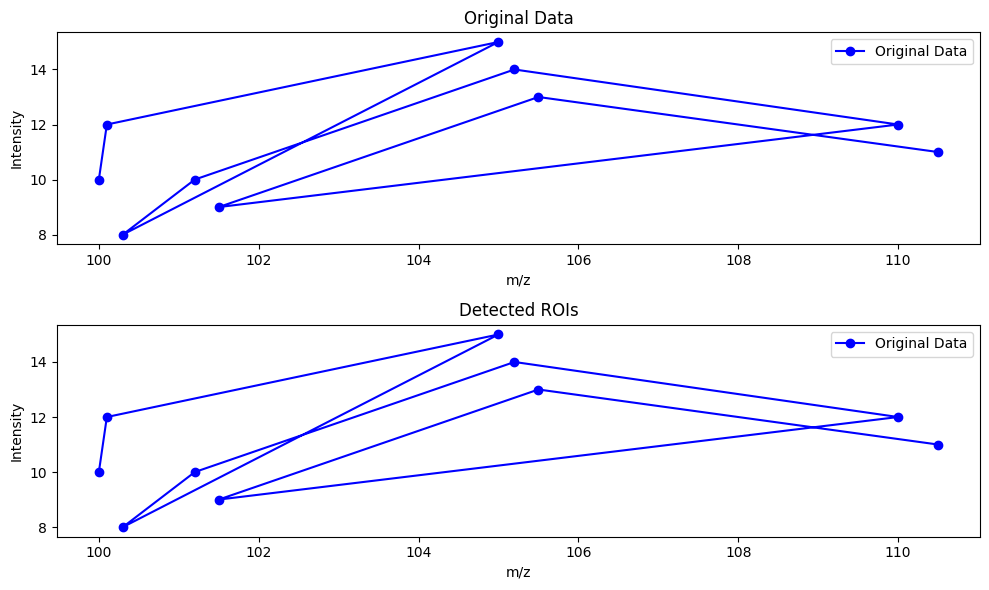

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Synthetic data
mz_values = np.array([100.0, 100.1, 105.0, 100.3, 101.2, 105.2, 110.0, 101.5, 105.5, 110.5])
intensity_values = np.array([10, 12, 15, 8, 10, 14, 12, 9, 13, 11])

# Algorithm parameters
mu = 30
pmin = 3
wmin = 5
wmax = 10
snr_thr = 10

# Run centWave algorithm
roi_list = centwave_algorithm(mz_values, intensity_values, mu, pmin, wmin, wmax, snr_thr)

# Plot the results
plt.figure(figsize=(10, 6))

# Plot the original data
plt.subplot(2, 1, 1)
plt.plot(mz_values, intensity_values, 'bo-', label='Original Data')
plt.title('Original Data')
plt.xlabel('m/z')
plt.ylabel('Intensity')
plt.legend()

# Plot the detected ROIs
plt.subplot(2, 1, 2)
plt.plot(mz_values, intensity_values, 'bo-', label='Original Data')
for roi in roi_list:
    plt.axvspan(roi.start, roi.end, alpha=0.3, color='orange', label='Detected ROI')

plt.title('Detected ROIs')
plt.xlabel('m/z')
plt.ylabel('Intensity')
plt.legend()

plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

Text(0.5, 1.0, 'Synthetic Mass Spectrum with Noise')

Text(0.5, 0, 'Time')

Text(0, 0.5, 'Intensity')

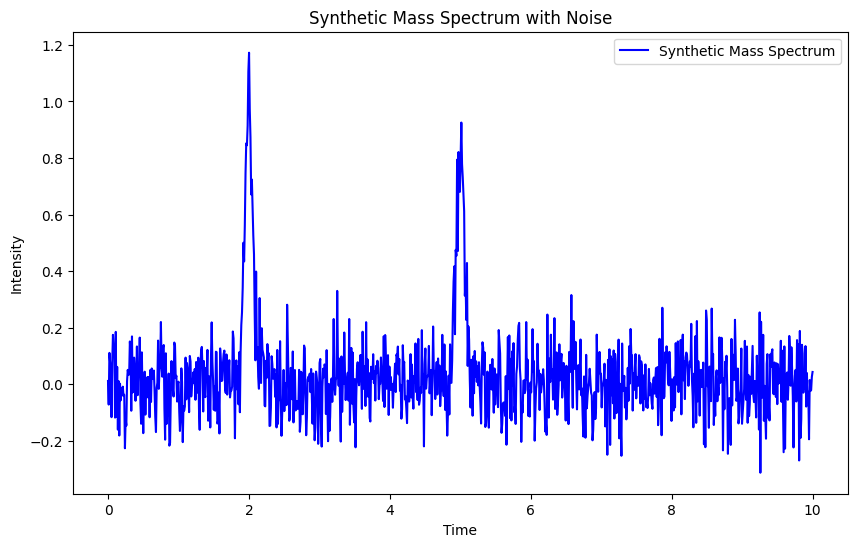

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Function to generate synthetic mass spectrometry data with noise
def generate_mass_spectrum(time, mz_values, intensity_values, retention_times, noise_level=0.1):
    spectrum = np.zeros_like(time)
    for m, i, rt in zip(mz_values, intensity_values, retention_times):
        spectrum += i * np.exp(-((time - rt) / 0.1)**2) * np.exp(-(time - m)**2 / (2 * noise_level**2))
    return spectrum + np.random.normal(0, noise_level, size=len(time))

# Parameters for synthetic data
time = np.linspace(0, 10, 1000)  # Time axis
mz_values = [2, 5, 8, 12]  # Mass-to-charge ratio values
intensity_values = [1, 0.8, 0.5, 0.7]  # Intensity values for each mass
retention_times = [2, 5, 7, 9]  # Retention times for each ion

# Generate synthetic mass spectrum data with noise
mass_spectrum = generate_mass_spectrum(time, mz_values, intensity_values, retention_times)

# Plot the time-frequency graph
plt.figure(figsize=(10, 6))
plt.plot(time, mass_spectrum, label='Synthetic Mass Spectrum', color='blue')
plt.title('Synthetic Mass Spectrum with Noise')
plt.xlabel('Time')
plt.ylabel('Intensity')
plt.legend()
plt.show()

Something is happening before the function is called.
Hello!
Something is happening after the function is called.


In [28]:
import math
import numpy
import pywt
from pywt import wavedec
from pywt import upcoef
from scipy import signal
import time

def ROI_construction(data_processed,precursor_tolerance,ms2_tolerance):
    '''
    Constructing all possible ROIs in a LC-MS run
    The combination of ROIs with missing value is performed in another functions

    Input:
    data_processed: (data after algorithm.preprocessing or directly from raw mzml) list[] dict{"precursor", "rt", "mz", "inten"}
    precursor_tolerance: (Combining precursors in tolerance) float
    ms2_tolerance: (ROI mz tolerance) float

    Output:
    data_roi: (All ROIs in a LC-MS run) list[] class Data_roi
    '''
    data_roi = []
    len_processed = len(data_processed)
    count_single = 0 # 计数scan的个数
    percentage_current = 0
    for data_single in data_processed:
        count_single += 1
        percentage_single = (count_single * 100) // len_processed
        if percentage_current != percentage_single:
            print(percentage_single, time.time())
            percentage_current = percentage_single
        precursor_exist = False
        for data_roi_single in data_roi:
            if precursor_tolerance > abs(data_single["precursor"] - data_roi_single._precursor):
                precursor_exist = True
                data_roi_single._rt_list.append(data_single["rt"])
                data_roi_single._eic_array.append(sum(data_single["inten"]))
                data_roi_single._mean_inten_list.append(numpy.mean(numpy.array(data_single["inten"])))
                data_roi_single._std_inten_list.append(numpy.std(numpy.array(data_single["inten"])))
                data_roi_single._num_inten_list.append(len(data_single["inten"]))
                data_single_array = numpy.zeros([len(data_single["mz"]), 2])
                data_single_array[:,0] = data_single["mz"]
                data_single_array[:,1] = data_single["inten"]
                data_single_array = data_single_array[data_single_array[:,1] != 0,:]
                data_single_array = data_single_array[numpy.argsort(-data_single_array[:,1])]
                for index_single in range(data_single_array.shape[0]):
                    mz_moving_list = data_roi_single._mz_moving_list
                    mz_exist = False
                    data_single_mz = data_single_array[index_single, 0]
                    mz_index = numpy.where(ms2_tolerance > abs(numpy.array(mz_moving_list) - data_single_mz))
                    if len(mz_index[0]) > 0:
                        mz_single_index = mz_index[0][0]
                        mz_feature = data_roi_single._mz_feature_moving_list[mz_single_index]
                        mz_exist = True
                        len_eic = len(mz_feature._eic_whole)
                        len_rt = len(data_roi_single._rt_list)
                        len_variance = len_rt - len_eic - mz_feature._roi_start
                        mz_feature._mz = (data_single_array[index_single, 0] + mz_feature._mz * mz_feature._mz_count) / (mz_feature._mz_count + 1)
                        mz_feature._mz_count = mz_feature._mz_count + 1
                        if 0 == len_variance:
                            mz_feature._eic_whole[len_eic - 1] = mz_feature._eic_whole[len_eic - 1] + data_single_array[index_single, 1]
                        if 1 == len_variance:
                            mz_feature._eic_whole.append(data_single_array[index_single, 1])

                        mz_moving_list[mz_single_index] = mz_feature._mz

                    if mz_exist == False:
                        mz_feature_new = Mz_feature()
                        mz_feature_new._mz = data_single_mz
                        mz_feature_new._mz_count = 1
                        mz_feature_new._roi_start = len(data_roi_single._rt_list) - 1
                        mz_feature_new._roi_moving = True
                        mz_feature_new._eic_whole = [data_single_array[index_single, 1]]
                        data_roi_single._mz_feature_moving_list.append(mz_feature_new)
                        data_roi_single._mz_moving_list.append(mz_feature_new._mz)

                for index_mz_feature in range(len(data_roi_single._mz_feature_moving_list)-1, -1, -1):
                    mz_feature = data_roi_single._mz_feature_moving_list[index_mz_feature]
                    len_eic = len(mz_feature._eic_whole)
                    len_rt = len(data_roi_single._rt_list)
                    len_variance = len_rt - len_eic - mz_feature._roi_start
                    if len_variance > 0:
                        mz_feature._roi_moving = False
                        mz_feature._roi_end = len_rt - 1
                        data_roi_single._mz_feature_list.append(data_roi_single._mz_feature_moving_list[index_mz_feature])
                        del data_roi_single._mz_feature_moving_list[index_mz_feature]
                        del data_roi_single._mz_moving_list[index_mz_feature]

                break 

        if precursor_exist==False:
            data_roi_single_new = Data_roi()
            data_roi_single_new._precursor = data_single["precursor"]
            data_roi_single_new._rt_list = [data_single["rt"]]
            data_roi_single_new._eic_array = [sum(data_single["inten"])]
            data_roi_single_new._mean_inten_list = [numpy.mean(numpy.array(data_single["inten"]))]
            data_roi_single_new._std_inten_list = [numpy.std(numpy.array(data_single["inten"]))]
            data_roi_single_new._num_inten_list = [len(data_single["inten"])]
            data_roi_single_new._mz_feature_list = []
            data_roi_single_new._mz_feature_moving_list = []
            data_roi_single_new._mz_moving_list = []
            data_single_array = numpy.zeros([len(data_single["mz"]), 2])
            data_single_array[:, 0] = data_single["mz"]
            data_single_array[:, 1] = data_single["inten"]
            data_single_array = data_single_array[numpy.argsort(-data_single_array[:,1])]
            for index_single in range(data_single_array.shape[0]):
                mz_exist=False
                for index_mz_feature in range(len(data_roi_single_new._mz_feature_moving_list)):
                    mz_feature = data_roi_single_new._mz_feature_moving_list[index_mz_feature]
                    if ms2_tolerance > abs(mz_feature._mz - data_single_array[index_single,0]):
                        mz_exist=True
                        mz_feature._mz = (data_single_array[index_single, 0]+mz_feature._mz * mz_feature._mz_count) / (mz_feature._mz_count + 1)
                        mz_feature._mz_count = mz_feature._mz_count + 1
                        mz_feature._eic_whole[0] = mz_feature._eic_whole[0] + data_single_array[index_single,1]
                        break

                if mz_exist == False:
                    mz_feature_new = Mz_feature()
                    mz_feature_new._mz = data_single_array[index_single,0]
                    mz_feature_new._mz_count = 1
                    mz_feature_new._roi_start = 0#这里本来应该是len(data_roi_single_new._rt_list)-1，考虑到新建立的data_roi，这里直接置零
                    mz_feature_new._roi_moving = True
                    mz_feature_new._eic_whole = [data_single_array[index_single,1]]
                    data_roi_single_new._mz_feature_moving_list.append(mz_feature_new)

            for mz_feature in data_roi_single_new._mz_feature_moving_list:
                data_roi_single_new._mz_moving_list.append(mz_feature._mz)

            data_roi.append(data_roi_single_new)

    for data_single in data_roi:
        for index_mz_feature in range(len(data_single._mz_feature_moving_list)-1, -1, -1):
            data_single._mz_feature_moving_list[index_mz_feature]._roi_moving = False
            data_single._mz_feature_moving_list[index_mz_feature]._roi_end = len(data_single._rt_list)
            data_single._mz_feature_list.append(data_single._mz_feature_moving_list[index_mz_feature])

    return data_roi


data_processed = [
    [100.0, 100.1, 105.0],
    [100.3, 101.2, 105.2, 110.0],
    [101.5, 105.5, 110.5]
]
precursor_tolerance = 0.5
ms2_tolerance = 1
ROI_construction(data_processed,precursor_tolerance,ms2_tolerance)

ModuleNotFoundError: No module named 'pywt'

In [31]:
numlist =[21,13,19,3,11,5,18]
numlist.sort
numlist[len(numlist) // 2]

<function list.sort(*, key=None, reverse=False)>

3